# **Infer `Cellmask` and `Nucleus`**

***Prior to this notebook, you should have already run through [1.0_image_setup](1.0_image_setup.ipynb).***

In notebooks 1.1 through 1.8, we will go over the implementation of `infer-subc` in the Napari plugin called  `organelle-segmenter-plugin`. The steps outlined in each notebook correlate to the workflow steps from the plugin. Here, you will gain knowledge of what `infer-subc` functions are involved in each of those steps.

The segmentation workflows are completely independent of each other and can be run in any order. The current notebook segments the `cell mask` and `nucleus` based on a multichannel input image. See below for more details on the input image type required. Consider the other versions of notebooks 1.1 outlined below as well.

## **SANDBOX FOR: Improved cell/nuclei segmentation**
<ins>Goals:</ins> Improve cell mask segmentation by implementing a machine learning approach. For comparison, the original masks_C workflow (without nuclei is included first).

Current thought process:
1. Segment nuclei manually from the inverse of a composite image (based on MCZ/ZC updates) -- this is actually very similar or exactly the same as what is done in 1.1a/b (see [NEW_infer-nuc_from-inverse-cyto.ipynb](NEW_infer-nuc_from-inverse-cyto.ipynb) notebook)
2. Input the PM staining and the nuclei segmentation into CellPose
3. POSSIBLY: add a trainable option to improve cyto3 model for iAstrocytes and iNeurons

--------------


---------------------
----------
# **IMPORTS AND LOAD IMAGE**
Details about the functions included in this subsection are outlined in the [`1.0_image_setup`](1.0_image_setup.ipynb) notebook. Please visit that notebook first if you are confused about any of the code included here.

#### &#x1F3C3; **Run code; no user input required**

In [ ]:
from pathlib import Path
import os
import seaborn as sns

import numpy as np
import pandas as pd
import napari
from napari.utils.notebook_display import nbscreenshot

from skimage.morphology import binary_dilation, binary_erosion

from infer_subc.core.file_io import (read_czi_image, 
                                     export_inferred_organelle,
                                     import_inferred_organelle,
                                     list_image_files,
                                     sample_input)
from infer_subc.core.img import *
from infer_subc.organelles.membrane import *
from infer_subc.organelles.nuclei import infer_nuclei_fromcytoplasm

%load_ext autoreload
%autoreload 2

viewer = napari.Viewer()

27-Oct-26 12:41:16 - vispy    - WARNING  - QWindowsWindow::setGeometry: Unable to set geometry 2172x1322+1626-1516 (frame: 2188x1361+1618-1547) on QWidgetWindow/"_QtMainWindowClassWindow" on "\\.\DISPLAY2". Resulting geometry: 1736x1056+1625-1523 (frame: 1752x1095+1617-1554) margins: 8, 31, 8, 8 minimum size: 385x506 MINMAXINFO maxSize=0,0 maxpos=0,0 mintrack=401,545 maxtrack=0,0)
27-Oct-26 12:41:16 - vispy    - WARNING  - QWindowsWindow::setGeometry: Unable to set geometry 544x506+1625-1523 (frame: 566x562+1614-1568) on QWidgetWindow/"_QtMainWindowClassWindow" on "\\.\DISPLAY3". Resulting geometry: 818x1010+1628-1508 (frame: 840x1066+1617-1553) margins: 11, 45, 11, 11 minimum size: 385x505 MINMAXINFO maxSize=0,0 maxpos=0,0 mintrack=792,1066 maxtrack=0,0)


: 

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following information about your data: `sample_data_type`, `data_root_path`, `in_data_path`, `im_type`, and `out_data_path`.

In [ ]:
### USER INPUT REQUIRED ###
sample_data_type = None


# Edit locations indicated by "USER SPECIFIED".
# data_root_path = Path(r"C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data")

# MCZ
# in_data_path = Path(r"J:\Cohen Lab\Maria Clara\2_Lab data\1_Multispectral data\2026\iAstrocytes Differentiation\iAstrocytes Differentiation - Deconvolved\tiff\iPSCs")
# in_data_path = Path(r"J:\Cohen Lab\Maria Clara\2_Lab data\1_Multispectral data\2026\iAstrocytes Differentiation\iAstrocytes Differentiation - Deconvolved\tiff\iN day21\new")
# MG
# in_data_path = Path(r"C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data")
# KK
in_data_path = Path(r"J:\Cohen Lab\Kajal\For Shannon\iAstroD28\Deconvolution")
in_data_path = Path(r"J:\Cohen Lab\Kajal\For Shannon\iNeuronsD14\Deconvolution")

im_type = ".tiff"

# out_data_path = 

# MCZ
# seg_paths = {'cell': Path(r"J:\Cohen Lab\Maria Clara\2_Lab data\09_2026_Napari\iAstrocytes Napari\Mask cell"),
#              'nuc': Path(r"J:\Cohen Lab\Maria Clara\2_Lab data\09_2026_Napari\iAstrocytes Napari\Nuclei")}
# seg_paths = {'cell': Path(r"J:\Cohen Lab\Maria Clara\2_Lab data\09_2026_Napari\iAstrocytes Napari\iPSCs mask D repeat"), # 'cell': Path(r"J:\Cohen Lab\Maria Clara\2_Lab data\09_2026_Napari\iAstrocytes Napari\Mask cell"),
#              'nuc': Path(r"J:\Cohen Lab\Maria Clara\2_Lab data\09_2026_Napari\iAstrocytes Napari\Nuclei")}
# MG
# seg_paths = {'cell': Path(r"C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\202610012_test-seg\cell_masks"),
#              'nuc': Path(r"C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\202610012_test-seg\cell_masks")}
# KK
# seg_paths = {'masks_C': Path(r"J:\Cohen Lab\Kajal\For Shannon\iAstroD28\Segmentation")}
seg_paths = {'masks_C': Path(r"J:\Cohen Lab\Kajal\For Shannon\iNeuronsD14\Segmentation")}
# seg_paths = {'cell': Path(r"J:\Cohen Lab\Kajal\For Shannon\iAstroD28\Segmentation"),
#              'nuc': Path(r"J:\Cohen Lab\Kajal\For Shannon\iAstroD28\Segmentation")}

#### &#x1F3C3; **Run code; no user input required**

In [3]:
# If sample_data_type is set to "neuron_1", "astrocyte", "neuron_2" or "iPSC" then the sample data is used and the directories are set
if sample_data_type != None:
    data_root_path, im_type, in_data_path, out_data_path = sample_input(sample_data_type)

# Create the output directory to save the segmentation outputs in.
# if not Path.exists(out_data_path):
#     Path.mkdir(out_data_path)
#     print(f"making {out_data_path}")

# if not Path.exists(vis_path):
#     Path.mkdir(vis_path)
#     print(f"making {vis_path}")

# Create a list of the file paths for each image in the input folder. Select test image path.
img_file_list = list_image_files(in_data_path,im_type)
pd.set_option('display.max_colwidth', None)
pd.DataFrame({"Image Name":img_file_list})

,Image Name
0,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\02242026_ZS_iPSCs_SOX9NFIA1_BR02_N07_Unmixing_cmle.ome.tiff
1,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\03172026_ZS_iPSCs_SOX9NFIA1_BR03_N03_Unmixing_cmle.ome.tiff
2,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\04092026_ZS_iAtro_day21_SOX9NFIA1_BR05_N07_Unmixing_cmle.ome.tiff
3,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\04092026_ZS_iAtro_day21_SOX9NFIA1_BR05_N11_Unmixing_cmle.ome.tiff
4,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img11_zstack_Unmixing_decon.ome.tiff
5,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\11192025_iNeurons_day_14_BFP2EEA1_mTurLAMP1_OxVenSiT_mAppRab11_PM_img18_zstack_Unmixing_decon.ome.tiff
6,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome.tiff
7,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome.tiff


#### &#x1F6D1; &#x270D; **User Input Required:**

Use the list above to specify which image you wish to analyze based on its index: `test_img_n`

In [10]:
#### USER INPUT REQUIRED ###
test_img_n = 7

#### &#x1F3C3; **Run code; no user input required**

In [11]:
# Read in the image and metadata as an ndarray and dictionary from the test image selected above. 
test_img_name = img_file_list[test_img_n]
img_data,meta_dict = read_czi_image(test_img_name)

# Define some of the metadata features and print them.
channel_names = meta_dict['name']
meta = meta_dict['metadata']['aicsimage']
scale = meta_dict['scale']
channel_axis = meta_dict['channel_axis']
file_path = meta_dict['file_name']
file_name = str(meta_dict['file_name']).split("\\")[-1]

print("Metadata information")
print(f"File path: {file_path}")
print(f"File name: {file_name}")
for i in list(range(len(channel_names))):
    print(f"Channel {i} name: {channel_names[i]}")
print(f"Scale (ZYX): {scale}")
print(f"Channel axis: {channel_axis}")

# get matching segmentations
# meta_dict['file_name'] = Path('J:/Cohen Lab/Kajal/For Shannon/iAstroD28/Deconvolution/04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img10_zstack_Unmix_trunc_.ome.tiff')
to_import = ['cell', 'nuc']
segs = {}

for organelle in to_import:
    seg = import_inferred_organelle(organelle, meta_dict, Path(seg_paths[organelle]), ".tiff")
    segs[organelle] = seg
    print(f"Imported {organelle} segmentation.")


Metadata information
File path: C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome.tiff
File name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome.tiff
Channel 0 name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome :: Channel 0
Channel 1 name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome :: Channel 1
Channel 2 name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome :: Channel 2
Channel 3 name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome :: Channel 3
Channel 4 name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome :: Channel 4
Channel 5 name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome :: Channel 5
Channel 6 name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome :: Channel 6
Channel 7 name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome :: Channel 7
Channel 8 name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome :: Channel 8
Channel 9 name: 20260813_wtc_ipsc_p47_ALLwe

Proceed to Napari window to view your selected image.

IF SAVING IMAGES FOR FIGURES: 
Adjust the contrast, coloring, and slice in the viewer, then run the next cell to save the merged image and each channel to the output directory.


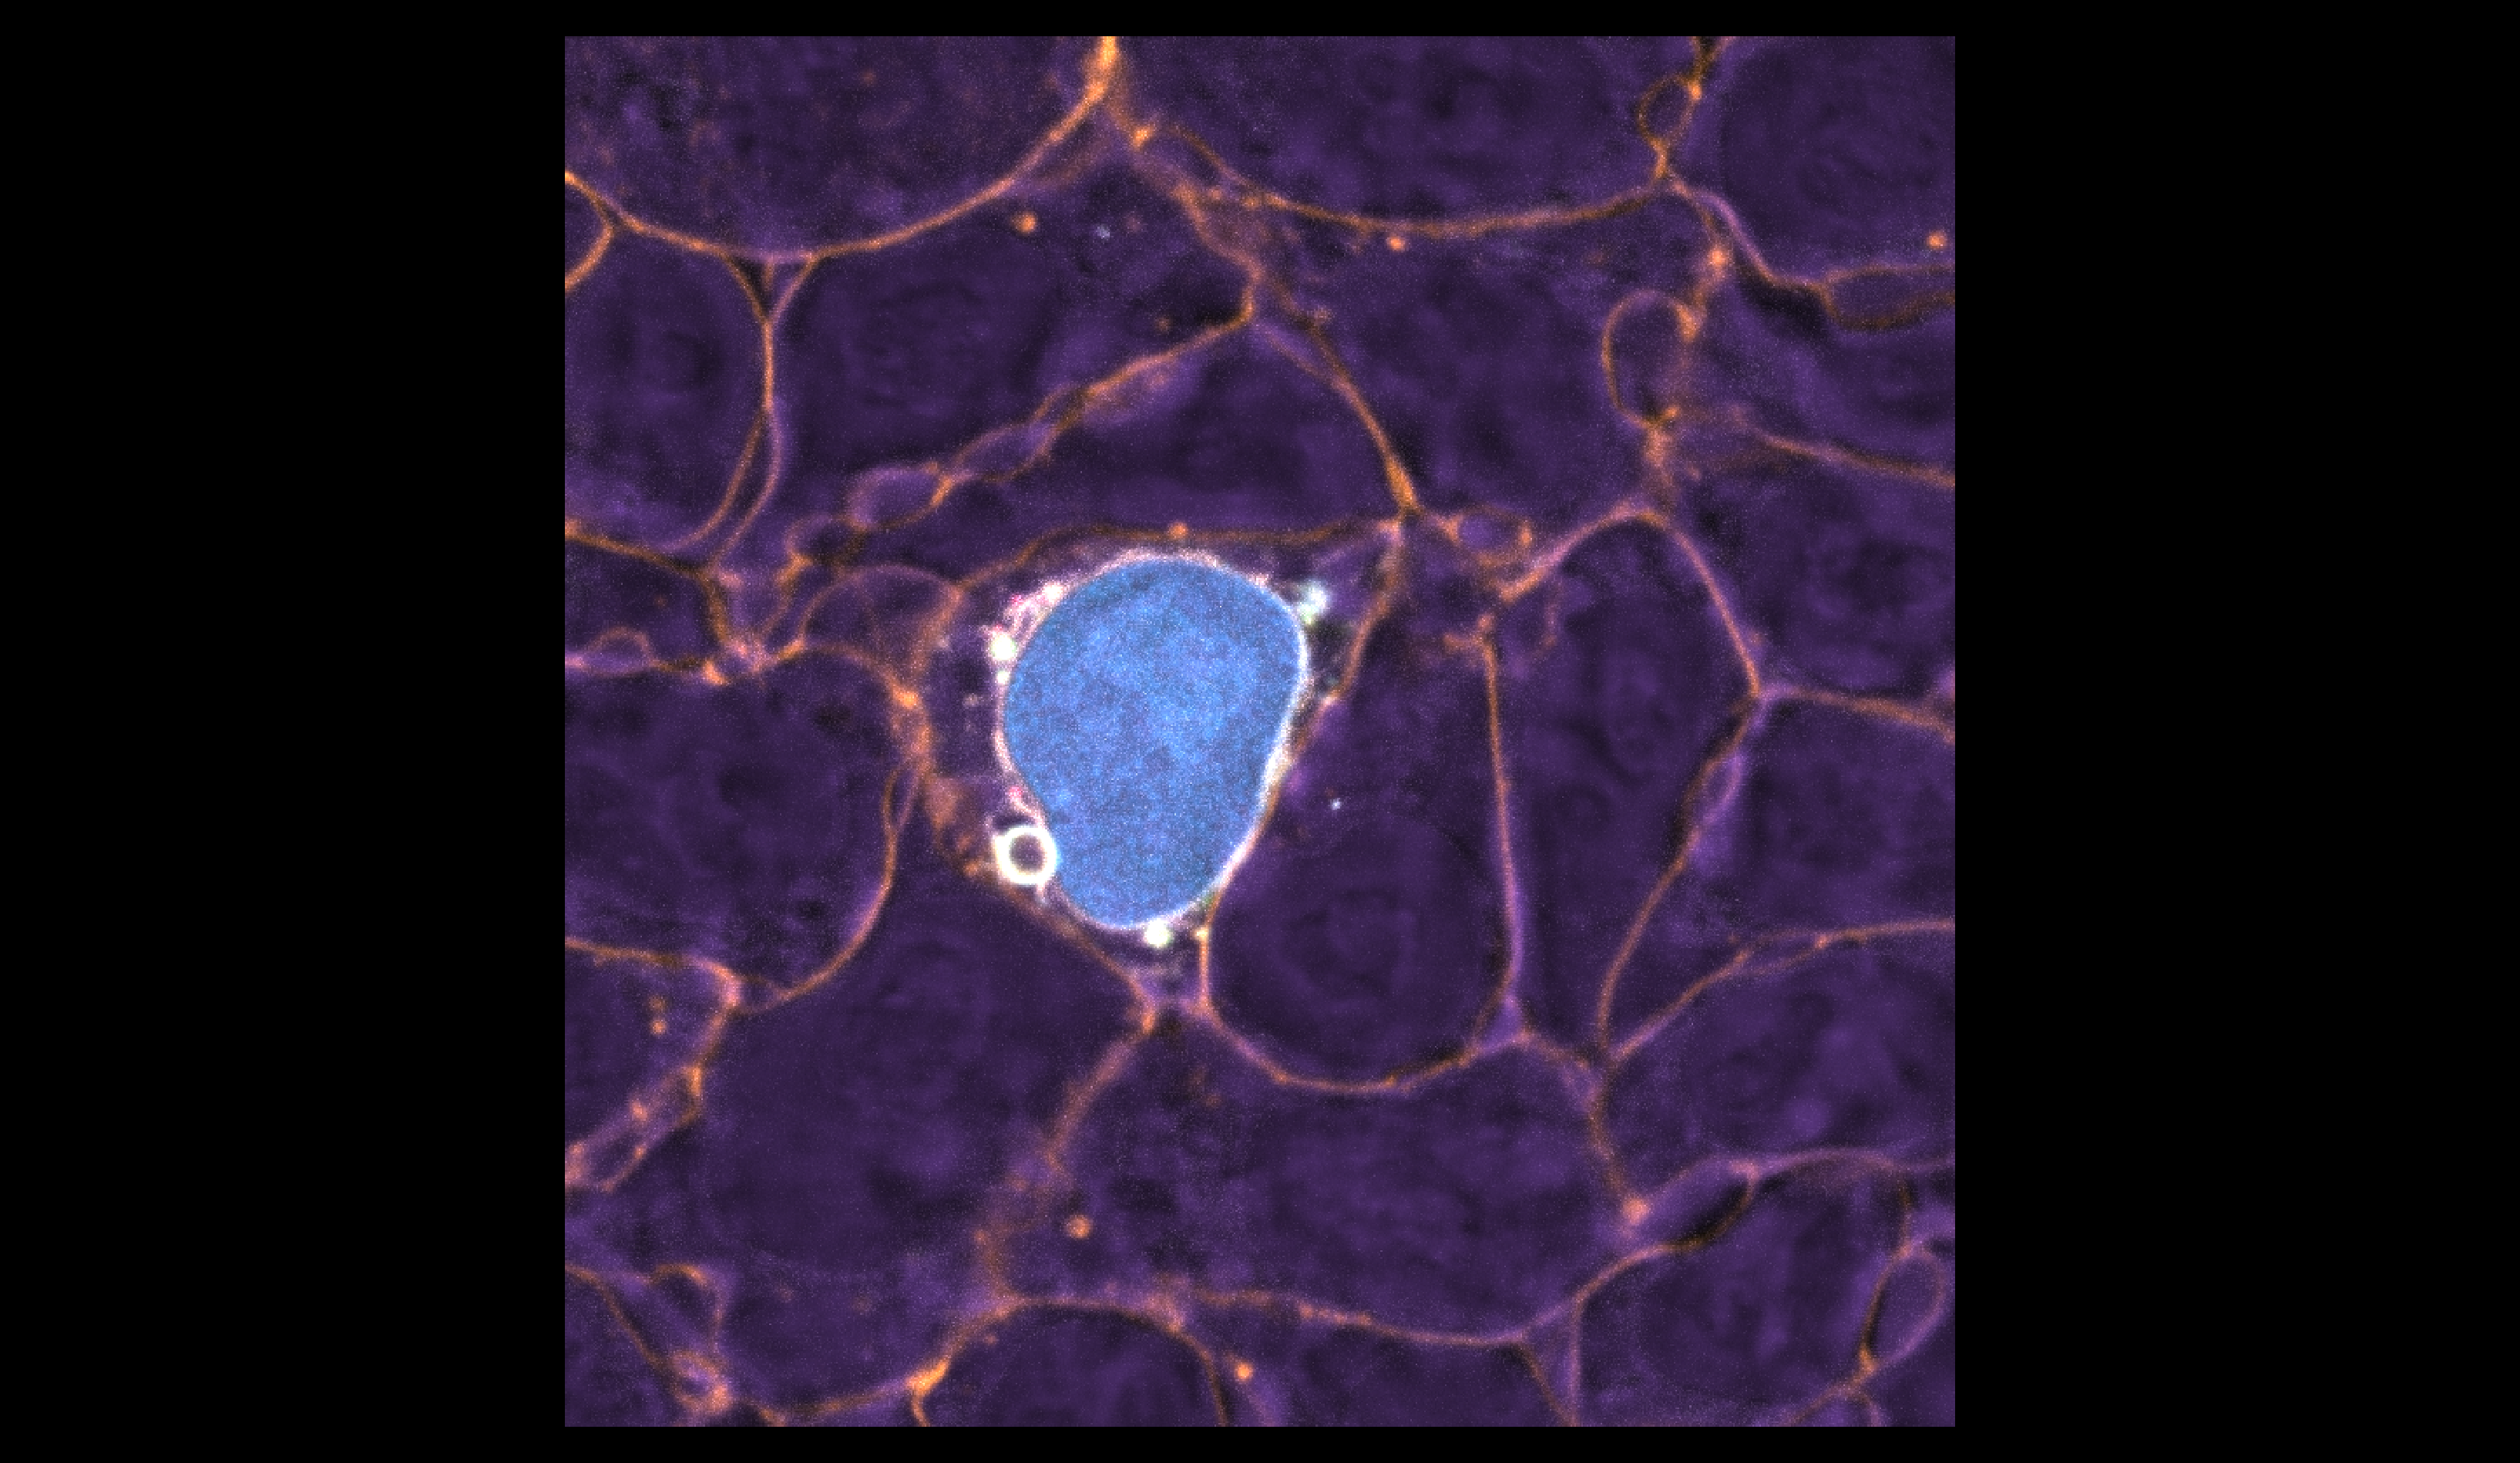

In [12]:
# open viewer and add images
viewer.layers.clear()
color_map = sns.color_palette("Paired").as_hex()
for i in list(range(len(channel_names))):
    # add image to viewer
    viewer.add_image(img_data[i],
                     scale=scale,
                     name=f"Channel {i}",
                     blending='additive',
                     colormap=color_map[i])
viewer.grid.enabled = False
viewer.reset_view()
print("Proceed to Napari window to view your selected image.")
print("\nIF SAVING IMAGES FOR FIGURES: \nAdjust the contrast, coloring, and slice in the viewer, then run the next cell to save the merged image and each channel to the output directory.")

# screenshot viewer
nbscreenshot(viewer, canvas_only = True)

In [13]:
### INSTRUCTIONS: ###
### Adjust the contrast & coloring of the channel in the viewer
### Then run this script to save the merged image and each channel to the output directory.
vis_path = Path(r"C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\202610012_test-seg\images_for_figures")

# turn all channels off and turn on the merged image to save it
for layer in viewer.layers:
    layer.visible = False

# turn on each channel separately and save it to the output directory
for i, layer in enumerate(viewer.layers):
    layer.visible = True
    viewer.screenshot(path = str(vis_path / f"{file_name}_ch{i}.png"), canvas_only = True)
    layer.visible = False

# turn on the merged image and save it to the output directory
for layer in viewer.layers:
    layer.visible = True

viewer.screenshot(path = str(vis_path / f"{file_name}_merged.png"), canvas_only = True)

array([[[  0,   0,   0, 255],
        [  0,   0,   0, 255],
        [  0,   0,   0, 255],
        ...,
        [  0,   0,   0, 255],
        [  0,   0,   0, 255],
        [  0,   0,   0, 255]],

       [[  0,   0,   0, 255],
        [  0,   0,   0, 255],
        [  0,   0,   0, 255],
        ...,
        [  0,   0,   0, 255],
        [  0,   0,   0, 255],
        [  0,   0,   0, 255]],

       [[  0,   0,   0, 255],
        [  0,   0,   0, 255],
        [  0,   0,   0, 255],
        ...,
        [  0,   0,   0, 255],
        [  0,   0,   0, 255],
        [  0,   0,   0, 255]],

       ...,

       [[  0,   0,   0, 255],
        [  0,   0,   0, 255],
        [  0,   0,   0, 255],
        ...,
        [  0,   0,   0, 255],
        [  0,   0,   0, 255],
        [  0,   0,   0, 255]],

       [[  0,   0,   0, 255],
        [  0,   0,   0, 255],
        [  0,   0,   0, 255],
        ...,
        [  0,   0,   0, 255],
        [  0,   0,   0, 255],
        [  0,   0,   0, 255]],

       [[  0

In [14]:
# add segmentations to veiwer
for organelle, seg in segs.items():
    viewer.add_image(seg, name=organelle,scale=scale, blending='additive', opacity=0.3)

In [ ]:
# turn off all overlays
for organelle in segs.keys():
    viewer.layers[organelle].visible = False

for organelle in segs.keys():
    viewer.layers[organelle].visible = True
    # merge + overlays
    viewer.screenshot(path = str(vis_path / f"{file_name}_{organelle}-overlay.png"), canvas_only = True)

print("Go to napari viewer & manually save ER-int + nuc overlay")